# H&M Customer Segmentation — Phase 7
## Cluster Profiling, Statistical Validation & Segment Naming

## Mục tiêu

Phase 6 đã tạo `cluster_id` kỹ thuật. Phase 7 trả lời:

1. Mỗi cluster khác các cluster còn lại ở điểm nào?
2. Cluster chiếm bao nhiêu customer và bao nhiêu observed spending?
3. R/F/M và các Extended features cao/thấp ở mức nào so với toàn population?
4. Khác biệt giữa các cluster có đủ lớn về mặt thống kê không?
5. Có thể đặt tên business cho cluster bằng **rule minh bạch** hay không?
6. Customer nào thuộc segment nào sau khi đặt tên?

### Nguyên tắc

- Không gọi `cluster 0 = VIP` trước khi profile.
- `cluster_id` không có thứ tự hay ý nghĩa business.
- Tên segment dựa trên **measured profile**, không dựa vào số cluster.
- P-value không đủ: với dữ liệu lớn, phải đọc cả **effect size**.
- Metadata như age/membership chủ yếu dùng để **profile**, không tự động quyết định giá trị khách hàng.
- Phase 7 chưa code cứng marketing action. Phase 8 mới ánh xạ segment → marketing objective → recommendation.

## 0. Input / Output

Input:

```text
data/features/
├── customer_features_master.parquet
└── phase6_candidate_feature_set.csv

data/results/
└── customer_cluster_assignments.parquet

data/models/
├── final_cluster_model.joblib
└── final_preprocessor.joblib
```

Output:

```text
data/results/
└── customer_segment_assignments.parquet

reports/
├── figures/
│   └── phase7_cluster_profiling/
└── tables/
    └── phase7_cluster_profiling/
```

In [1]:
import sys
from sklearn.base import BaseEstimator, TransformerMixin

class OutlierCapper(BaseEstimator, TransformerMixin):
    def __init__(self, method='iqr', factor=3.0, clip_lower_zero=True):
        self.method = method
        self.factor = factor
        self.clip_lower_zero = clip_lower_zero

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X).copy()
        if hasattr(self, 'lower_bounds_') and hasattr(self, 'upper_bounds_'):
            for i, col in enumerate(X_df.columns):
                X_df[col] = np.clip(X_df[col], self.lower_bounds_[i], self.upper_bounds_[i])
        return X_df.to_numpy()

sys.modules['__main__'].OutlierCapper = OutlierCapper

from pathlib import Path
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import kruskal, mannwhitneyu

pd.set_option("display.max_columns", 220)
pd.set_option("display.width", 240)

ROOT = Path("..")
FEATURE_DIR = ROOT / "data" / "features"
MODEL_DIR = ROOT / "data" / "models"
RESULT_DIR = ROOT / "data" / "results"

FIG_DIR = ROOT / "reports" / "figures" / "phase7_cluster_profiling"
TABLE_DIR = ROOT / "reports" / "tables" / "phase7_cluster_profiling"

for d in [FIG_DIR, TABLE_DIR, RESULT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

MASTER_PATH = FEATURE_DIR / "customer_features_master.parquet"
FEATURE_SET_PATH = FEATURE_DIR / "phase6_candidate_feature_set.csv"
ASSIGN_PATH = RESULT_DIR / "customer_cluster_assignments.parquet"

MODEL_PATH = MODEL_DIR / "final_cluster_model.joblib"
PREPROCESSOR_PATH = MODEL_DIR / "final_preprocessor.joblib"

for p in [MASTER_PATH, FEATURE_SET_PATH, ASSIGN_PATH]:
    print(f"{p}: {'OK' if p.exists() else 'MISSING'}")

RANDOM_STATE = 42
KW_SAMPLE_PER_CLUSTER = 50_000
PAIRWISE_SAMPLE_PER_CLUSTER = 20_000
BOXPLOT_SAMPLE_PER_CLUSTER = 5_000

# Robust profile state threshold.
PROFILE_THRESHOLD = 0.50

..\data\features\customer_features_master.parquet: OK
..\data\features\phase6_candidate_feature_set.csv: OK
..\data\results\customer_cluster_assignments.parquet: OK


# A. LOAD & JOIN

## 1. Join customer features với technical cluster ID

Join phải giữ nguyên customer universe từ Phase 6.

In [2]:
master = pd.read_parquet(MASTER_PATH)
assignments = pd.read_parquet(ASSIGN_PATH)
phase6_features = pd.read_csv(FEATURE_SET_PATH)

MODEL_FEATURES = phase6_features["feature"].tolist()

# Gán trực tiếp cluster_id theo thứ tự khách hàng, tránh tốn RAM khi merge chuỗi hex:
profile = master.copy()
profile["cluster_id"] = assignments["cluster_id"].values

assert len(profile) == len(assignments)
assert profile["customer_id"].duplicated().sum() == 0
assert profile["cluster_id"].isna().sum() == 0

CLUSTERS = sorted(profile["cluster_id"].unique().tolist())

print("Customers:", len(profile))
print("Clusters:", CLUSTERS)
print("Model features:", MODEL_FEATURES)
display(profile.head())


Customers: 1362281
Clusters: [0, 1, 2, 3]
Model features: ['recency_days', 'frequency_purchase_days', 'monetary_total_spend', 'product_diversity', 'product_type_diversity']


,customer_id,first_purchase_date,last_purchase_date,recency_days,frequency_purchase_days,monetary_total_spend,item_frequency,interval_count,mean_interpurchase_days,median_interpurchase_days,std_interpurchase_days,min_interpurchase_days,max_interpurchase_days,avg_item_price,avg_spend_per_purchase_day,product_diversity,garment_group_diversity,colour_diversity,product_type_diversity,department_diversity,section_diversity,channel_diversity,dominant_channel_share,age,club_member_status,fashion_news_frequency,FN,Active,customer_tenure_days,items_per_purchase_day,cluster_id
0,8161cf725cd125586a9811433f957f5c6d47801f955517...,2018-09-26,2020-09-01,22,25,4.119034,117,24.0,29.416667,16.5,35.887404,1.0,164.0,0.035205,0.164761,96,18,21,26,39,17,2,0.897436,48.0,ACTIVE,NONE,NaN,NaN,706,4.680000,1
1,81d60d7dc77a8dcef9fc1ccfaf0011a58f20b97049b8ec...,2018-10-24,2020-07-11,74,12,0.997508,37,11.0,56.909091,45.0,50.106795,1.0,143.0,0.026960,0.083126,37,12,13,20,28,15,2,0.945946,53.0,ACTIVE,NONE,NaN,NaN,626,3.083333,3
2,8242e65d84adfde92b1170b176fabd1eb6676a15d04369...,2018-10-26,2018-10-26,698,1,0.025407,1,NaN,NaN,NaN,NaN,NaN,NaN,0.025407,0.025407,1,1,1,1,1,1,1,1.000000,49.0,ACTIVE,REGULARLY,1.0,1.0,0,1.000000,0
3,826a09c6c6c9dee397a3a22165fe2be8846fa2575eaf93...,2018-10-26,2019-03-15,558,4,0.223559,10,3.0,46.666667,42.0,21.385353,28.0,70.0,0.022356,0.055890,10,7,7,8,9,5,1,1.000000,73.0,ACTIVE,NONE,NaN,NaN,140,2.500000,0
4,83e4096636a357e0334f37567182e0f87350f725c5ba7e...,2018-09-21,2020-09-19,4,38,3.078797,114,37.0,19.702703,14.0,20.226310,1.0,88.0,0.027007,0.081021,111,18,20,35,46,20,2,0.561404,53.0,ACTIVE,NONE,NaN,NaN,729,3.000000,1


## 2. Chọn biến để profiling

### Model features
Các biến thực sự tạo cluster.

### Business/profile-only features
Nếu tồn tại:
- item frequency;
- average item price;
- spend per purchase day;
- fashion diversity;
- customer tenure;
- age;
- channel preference.

Biến profile-only giúp **hiểu** cluster, nhưng không được viết như thể chúng tạo ra cluster nếu chúng không nằm trong final model.

In [3]:
PROFILE_EXTRA_CANDIDATES = [
    "item_frequency",
    "avg_item_price",
    "avg_spend_per_purchase_day",
    "product_diversity",
    "product_type_diversity",
    "garment_group_diversity",
    "colour_diversity",
    "department_diversity",
    "section_diversity",
    "dominant_channel_share",
    "channel_diversity",
    "items_per_purchase_day",
    "customer_tenure_days",
    "age"
]

PROFILE_EXTRA = [
    f for f in PROFILE_EXTRA_CANDIDATES
    if f in profile.columns and f not in MODEL_FEATURES
]

NUMERIC_PROFILE_FEATURES = list(dict.fromkeys(
    MODEL_FEATURES + PROFILE_EXTRA
))

print("Model features:", MODEL_FEATURES)
print("Profile-only numeric features:", PROFILE_EXTRA)

Model features: ['recency_days', 'frequency_purchase_days', 'monetary_total_spend', 'product_diversity', 'product_type_diversity']
Profile-only numeric features: ['item_frequency', 'avg_item_price', 'avg_spend_per_purchase_day', 'garment_group_diversity', 'colour_diversity', 'department_diversity', 'section_diversity', 'dominant_channel_share', 'channel_diversity', 'items_per_purchase_day', 'customer_tenure_days', 'age']


# B. CLUSTER SIZE & ECONOMIC CONTRIBUTION

## 3. Customer share + observed spending share

`monetary_total_spend` là observed cumulative spending trong dataset, không phải CLV dự báo.

In [4]:
cluster_size = (
    profile.groupby("cluster_id")
    .agg(
        customers=("customer_id", "size"),
        total_observed_spend=("monetary_total_spend", "sum"),
        median_observed_spend=("monetary_total_spend", "median")
    )
    .reset_index()
)

cluster_size["pct_customers"] = (
    cluster_size["customers"] / cluster_size["customers"].sum() * 100
)
cluster_size["pct_observed_spend"] = (
    cluster_size["total_observed_spend"] /
    cluster_size["total_observed_spend"].sum() * 100
)

cluster_size["spend_share_index"] = (
    cluster_size["pct_observed_spend"] /
    cluster_size["pct_customers"]
)

display(cluster_size)
cluster_size.to_csv(
    TABLE_DIR / "01_cluster_size_and_spend_share.csv",
    index=False
)

,cluster_id,customers,total_observed_spend,median_observed_spend,pct_customers,pct_observed_spend,spend_share_index
0,0,383758,55595.871712,0.093186,28.170253,6.284533,0.223091
1,1,138928,445659.926458,2.522153,10.198190,50.377206,4.939819
2,2,560287,122323.589492,0.171034,41.128592,13.827406,0.336199
3,3,279308,261066.586390,0.855898,20.502965,29.510855,1.439346


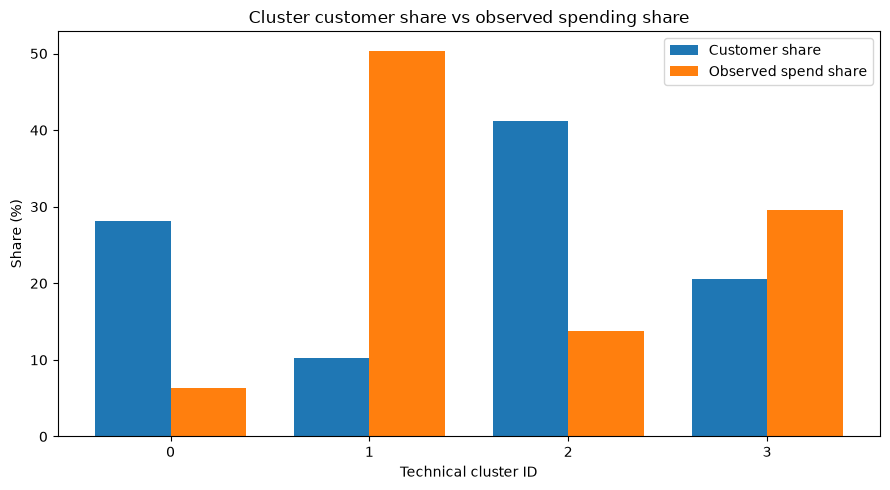

In [5]:
plot_df = cluster_size.sort_values("cluster_id").copy()
x = np.arange(len(plot_df))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - width/2, plot_df["pct_customers"], width, label="Customer share")
ax.bar(x + width/2, plot_df["pct_observed_spend"], width, label="Observed spend share")
ax.set_xticks(x)
ax.set_xticklabels(plot_df["cluster_id"].astype(str))
ax.set_xlabel("Technical cluster ID")
ax.set_ylabel("Share (%)")
ax.set_title("Cluster customer share vs observed spending share")
ax.legend()
fig.tight_layout()
fig.savefig(
    FIG_DIR / "01_customer_vs_spend_share.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

# C. RAW CLUSTER PROFILES

## 4. Mean / Median / IQR theo cluster

Vì nhiều customer variables bị skew, **median** được ưu tiên khi diễn giải. Mean vẫn được lưu để tham khảo.

In [6]:
summary_rows = []

for cluster_id in CLUSTERS:
    g = profile[profile["cluster_id"] == cluster_id]

    for feature in NUMERIC_PROFILE_FEATURES:
        s = pd.to_numeric(g[feature], errors="coerce").dropna()

        if len(s) == 0:
            continue

        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)

        summary_rows.append({
            "cluster_id": cluster_id,
            "feature": feature,
            "n_non_null": len(s),
            "coverage_pct_in_cluster": len(s) / len(g) * 100,
            "mean": s.mean(),
            "median": s.median(),
            "q1": q1,
            "q3": q3,
            "iqr": q3 - q1,
            "std": s.std()
        })

cluster_profile_long = pd.DataFrame(summary_rows)

display(cluster_profile_long.head(20))
cluster_profile_long.to_csv(
    TABLE_DIR / "02_cluster_profile_long.csv",
    index=False
)

cluster_medians = cluster_profile_long.pivot(
    index="cluster_id",
    columns="feature",
    values="median"
)

cluster_means = cluster_profile_long.pivot(
    index="cluster_id",
    columns="feature",
    values="mean"
)

cluster_medians.to_csv(TABLE_DIR / "03_cluster_medians.csv")
cluster_means.to_csv(TABLE_DIR / "04_cluster_means.csv")

display(cluster_medians)

,cluster_id,feature,n_non_null,coverage_pct_in_cluster,mean,median,q1,q3,iqr,std
0,0,recency_days,383758,100.000000,546.621076,550.000000,448.000000,652.000000,204.000000,115.921190
1,0,frequency_purchase_days,383758,100.000000,1.641975,1.000000,1.000000,2.000000,1.000000,1.192594
2,0,monetary_total_spend,383758,100.000000,0.144872,0.093186,0.049576,0.182983,0.133407,0.154716
3,0,product_diversity,383758,100.000000,4.743007,3.000000,2.000000,6.000000,4.000000,4.575934
4,0,product_type_diversity,383758,100.000000,2.984657,2.000000,1.000000,4.000000,3.000000,2.306591
5,0,item_frequency,383758,100.000000,5.432538,4.000000,2.000000,7.000000,5.000000,5.622198
6,0,avg_item_price,383758,100.000000,0.029769,0.025407,0.019051,0.033886,0.014835,0.018515
7,0,avg_spend_per_purchase_day,383758,100.000000,0.092104,0.067729,0.040627,0.112763,0.072136,0.088872
8,0,garment_group_diversity,383758,100.000000,2.622640,2.000000,1.000000,4.000000,3.000000,1.890148
9,0,colour_diversity,383758,100.000000,3.092780,2.000000,1.000000,4.000000,3.000000,2.323995


feature,age,avg_item_price,avg_spend_per_purchase_day,channel_diversity,colour_diversity,customer_tenure_days,department_diversity,dominant_channel_share,frequency_purchase_days,garment_group_diversity,item_frequency,items_per_purchase_day,monetary_total_spend,product_diversity,product_type_diversity,recency_days,section_diversity
cluster_id,,,,,,,,,,,,,,,,,
0,36.0,0.025407,0.067729,1.0,2.0,0.0,2.0,1.000000,1.0,2.0,4.0,2.500000,0.093186,3.0,2.0,550.0,2.0
1,31.0,0.027963,0.109935,2.0,20.0,673.0,33.0,0.864662,24.0,14.0,89.0,3.875000,2.522153,77.0,22.0,26.0,17.0
2,30.0,0.025946,0.064898,1.0,4.0,133.0,4.0,1.000000,2.0,3.0,7.0,2.428571,0.171034,6.0,4.0,123.0,3.0
3,30.0,0.025800,0.081120,2.0,12.0,575.0,16.0,0.861111,10.0,10.0,33.0,3.125000,0.855898,29.0,13.0,58.5,10.0


# D. ROBUST STANDARDIZED PROFILE

## 5. Tại sao không chỉ nhìn raw median?

Ví dụ:
- Monetary có đơn vị khác Recency;
- Diversity có scale nhỏ;
- một số biến rất skew.

Ta tạo **robust profile score**:

\[
score_{c,f}
=
rac{Median_{cluster(c),f}-Median_{global,f}}
{IQR_{global,f}}
\]

Nếu global IQR = 0, dùng global standard deviation làm fallback.

Diễn giải mặc định:

- `score <= -0.5` → Low
- `-0.5 < score < 0.5` → Medium
- `score >= 0.5` → High

Riêng `Recency`: **Low Recency = Active**, High Recency = Inactive.

In [7]:
global_stats = []

for f in NUMERIC_PROFILE_FEATURES:
    s = pd.to_numeric(profile[f], errors="coerce").dropna()

    q1 = s.quantile(.25)
    q3 = s.quantile(.75)
    iqr = q3 - q1
    std = s.std()

    scale = iqr if pd.notna(iqr) and iqr > 0 else std
    if not pd.notna(scale) or scale == 0:
        scale = 1.0

    global_stats.append({
        "feature": f,
        "global_median": s.median(),
        "global_q1": q1,
        "global_q3": q3,
        "global_iqr": iqr,
        "fallback_std": std,
        "profile_scale": scale
    })

global_stats = pd.DataFrame(global_stats)
global_stats.to_csv(
    TABLE_DIR / "05_global_profile_reference.csv",
    index=False
)

profile_score = cluster_medians.copy()

for f in profile_score.columns:
    ref = global_stats.loc[global_stats["feature"] == f].iloc[0]
    profile_score[f] = (
        cluster_medians[f] - ref["global_median"]
    ) / ref["profile_scale"]

display(profile_score.round(3))
profile_score.to_csv(TABLE_DIR / "06_cluster_robust_profile_scores.csv")

feature,age,avg_item_price,avg_spend_per_purchase_day,channel_diversity,colour_diversity,customer_tenure_days,department_diversity,dominant_channel_share,frequency_purchase_days,garment_group_diversity,item_frequency,items_per_purchase_day,monetary_total_spend,product_diversity,product_type_diversity,recency_days,section_diversity
cluster_id,,,,,,,,,,,,,,,,,
0,0.16,-0.059,-0.073,0.0,-0.375,-0.375,-0.333,0.000,-0.286,-0.286,-0.208,-0.158,-0.249,-0.238,-0.333,1.137,-0.286
1,-0.04,0.148,0.534,1.0,1.875,0.851,2.250,-0.920,3.000,1.429,3.333,0.493,3.713,3.286,1.889,-0.360,1.857
2,-0.08,-0.015,-0.114,0.0,-0.125,-0.133,-0.167,0.000,-0.143,-0.143,-0.083,-0.192,-0.122,-0.095,-0.111,-0.083,-0.143
3,-0.08,-0.027,0.120,1.0,0.875,0.672,0.833,-0.944,1.000,0.857,1.000,0.138,0.995,1.000,0.889,-0.267,0.857


## 6. Business-oriented profile

Để visualization dễ đọc:

- Recency được đảo dấu để **score cao = active/recent**.
- Các feature còn lại giữ nguyên hướng số học.

Bảng raw robust-score vẫn được lưu riêng để tránh mất ý nghĩa gốc.

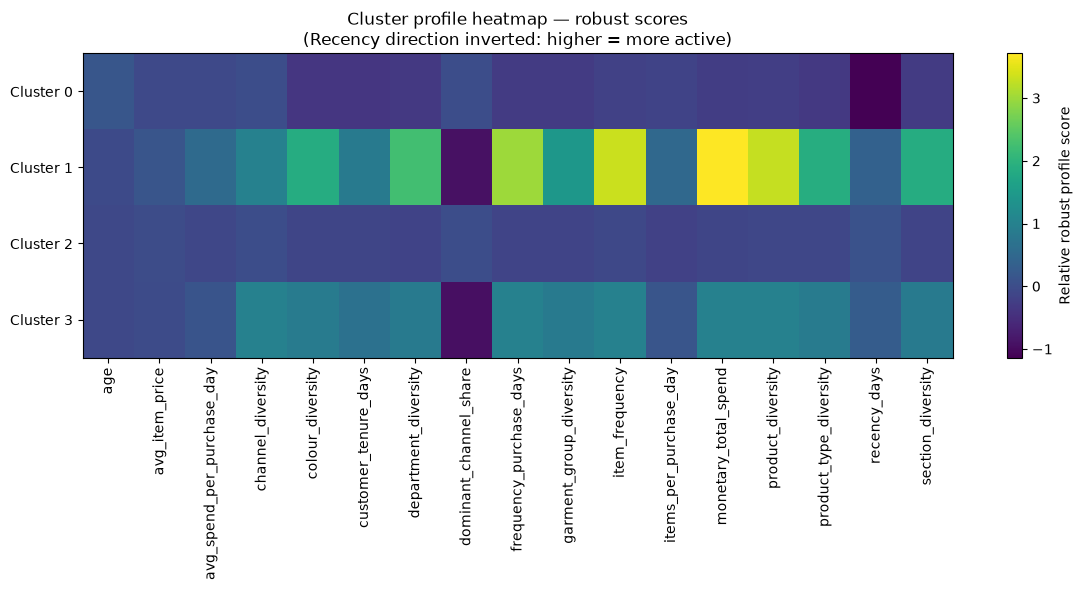

In [8]:
business_profile_score = profile_score.copy()

if "recency_days" in business_profile_score.columns:
    business_profile_score["recency_days"] = (
        -business_profile_score["recency_days"]
    )

business_profile_score.to_csv(
    TABLE_DIR / "07_business_oriented_profile_scores.csv"
)

fig, ax = plt.subplots(
    figsize=(max(10, len(business_profile_score.columns) * 0.7), 6)
)

im = ax.imshow(
    business_profile_score.values,
    aspect="auto"
)

ax.set_xticks(range(len(business_profile_score.columns)))
ax.set_xticklabels(
    business_profile_score.columns,
    rotation=90
)
ax.set_yticks(range(len(business_profile_score.index)))
ax.set_yticklabels(
    [f"Cluster {x}" for x in business_profile_score.index]
)

ax.set_title(
    "Cluster profile heatmap — robust scores\n"
    "(Recency direction inverted: higher = more active)"
)

fig.colorbar(im, ax=ax, label="Relative robust profile score")
fig.tight_layout()

fig.savefig(
    FIG_DIR / "02_cluster_profile_heatmap.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

# E. CORE RFM VISUALIZATION

## 7. Boxplots theo cluster

Với dataset lớn, boxplot dùng sample cố định theo cluster để tránh plotting quá nặng.

Biểu đồ phục vụ:
- nhìn overlap;
- nhìn median/IQR;
- phát hiện cluster có profile thật sự khác nhau hay chỉ khác centroid nhẹ.

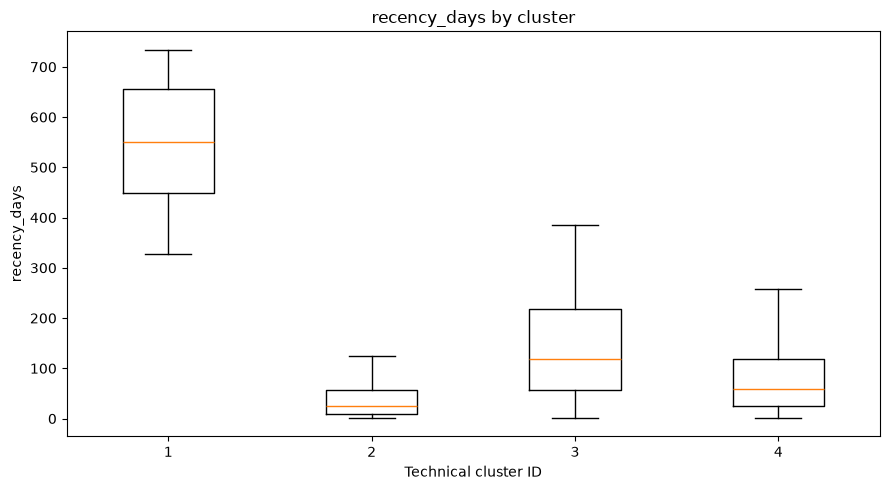

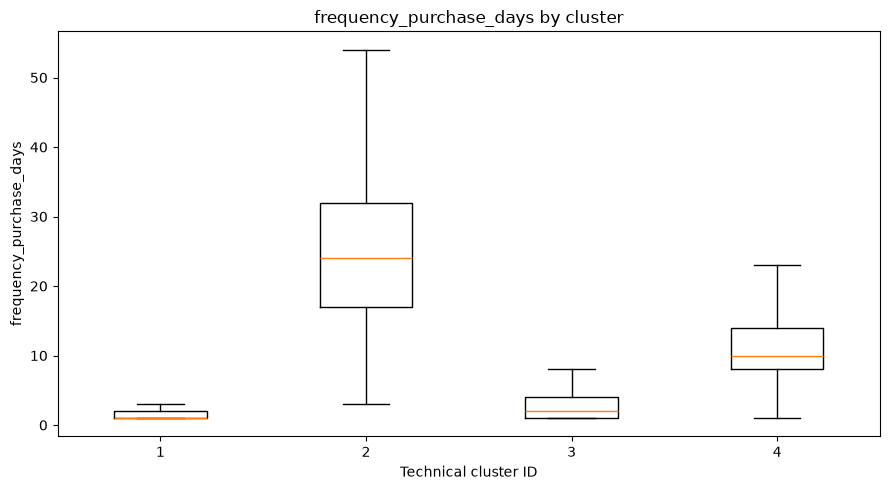

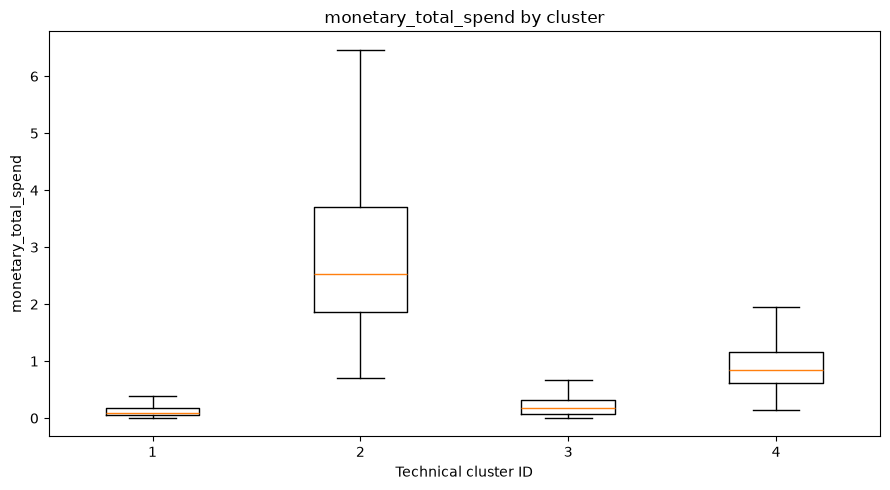

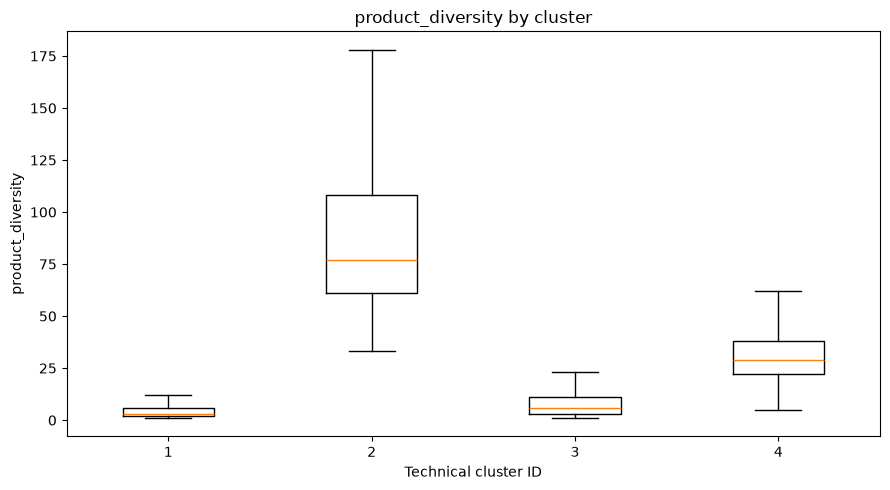

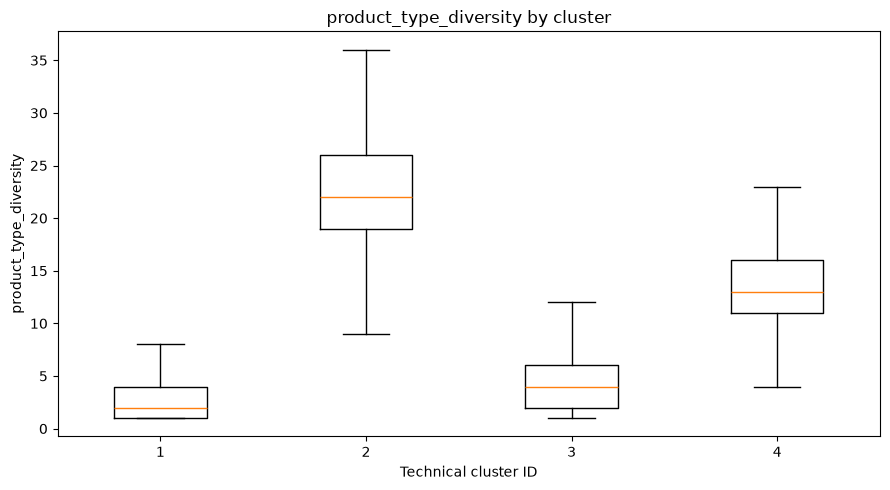

In [9]:
BOXPLOT_FEATURES = [
    f for f in [
        "recency_days",
        "frequency_purchase_days",
        "monetary_total_spend"
    ] + [
        x for x in MODEL_FEATURES
        if x not in [
            "recency_days",
            "frequency_purchase_days",
            "monetary_total_spend"
        ]
    ][:4]
    if f in profile.columns
]

rng = np.random.default_rng(RANDOM_STATE)

for feature in BOXPLOT_FEATURES:
    data = []
    labels = []

    for cluster_id in CLUSTERS:
        s = pd.to_numeric(
            profile.loc[
                profile["cluster_id"] == cluster_id,
                feature
            ],
            errors="coerce"
        ).dropna()

        if len(s) > BOXPLOT_SAMPLE_PER_CLUSTER:
            idx = rng.choice(
                len(s),
                size=BOXPLOT_SAMPLE_PER_CLUSTER,
                replace=False
            )
            s = s.iloc[idx]

        data.append(s.values)
        labels.append(str(cluster_id))

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.boxplot(
        data,
        label=labels,
        showfliers=False
    )
    ax.set_xlabel("Technical cluster ID")
    ax.set_ylabel(feature)
    ax.set_title(f"{feature} by cluster")
    fig.tight_layout()
    fig.savefig(
        FIG_DIR / f"03_boxplot_{feature}.png",
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()

# F. STATISTICAL VALIDATION

## 8. Kruskal–Wallis + effect size

Customer features thường skew và sample rất lớn, nên Phase 7 dùng Kruskal–Wallis cho numeric profile features.

### Quan trọng

Với hàng trăm nghìn customer, p-value rất dễ cực nhỏ. Vì vậy ta ưu tiên đọc thêm:

\[
\epsilon^2
=
rac{H-k+1}{n-k}
\]

Quy ước effect size tham khảo:

- `< 0.01` → negligible
- `0.01–<0.08` → small
- `0.08–<0.26` → medium
- `>= 0.26` → large

Để kiểm định không bị chi phối bởi population cực lớn, mỗi cluster lấy tối đa một sample cố định.

In [10]:
def effect_label(eps):
    if pd.isna(eps):
        return "unknown"
    if eps < 0.01:
        return "negligible"
    if eps < 0.08:
        return "small"
    if eps < 0.26:
        return "medium"
    return "large"

def bh_adjust(p_values):
    p = np.asarray(p_values, dtype=float)
    n = len(p)

    order = np.argsort(p)
    ranked = p[order]

    adjusted = np.empty(n, dtype=float)
    prev = 1.0

    for i in range(n - 1, -1, -1):
        rank = i + 1
        value = min(prev, ranked[i] * n / rank)
        adjusted[i] = value
        prev = value

    result = np.empty(n, dtype=float)
    result[order] = np.clip(adjusted, 0, 1)

    return result

kw_rows = []

for feature in NUMERIC_PROFILE_FEATURES:
    groups = []

    for cluster_id in CLUSTERS:
        s = pd.to_numeric(
            profile.loc[
                profile["cluster_id"] == cluster_id,
                feature
            ],
            errors="coerce"
        ).dropna()

        if len(s) > KW_SAMPLE_PER_CLUSTER:
            s = s.sample(
                n=KW_SAMPLE_PER_CLUSTER,
                random_state=RANDOM_STATE + int(cluster_id)
            )

        if len(s) > 0:
            groups.append(s.values)

    if len(groups) < 2:
        continue

    H, p = kruskal(*groups)

    n = sum(len(g) for g in groups)
    k = len(groups)

    epsilon_squared = max(
        0.0,
        (H - k + 1) / (n - k)
    ) if n > k else np.nan

    kw_rows.append({
        "feature": feature,
        "kruskal_H": H,
        "p_value": p,
        "epsilon_squared": epsilon_squared,
        "effect_size": effect_label(epsilon_squared),
        "test_sample_n": n,
        "n_clusters_tested": k
    })

kw_results = pd.DataFrame(kw_rows)

if len(kw_results):
    kw_results["fdr_q_value"] = bh_adjust(
        kw_results["p_value"].values
    )
    kw_results["statistically_significant_fdr_05"] = (
        kw_results["fdr_q_value"] < 0.05
    )

    kw_results = kw_results.sort_values(
        ["epsilon_squared", "fdr_q_value"],
        ascending=[False, True]
    )

display(kw_results)
kw_results.to_csv(
    TABLE_DIR / "08_kruskal_wallis_effect_size.csv",
    index=False
)

,feature,kruskal_H,p_value,epsilon_squared,effect_size,test_sample_n,n_clusters_tested,fdr_q_value,statistically_significant_fdr_05
3,product_diversity,167812.928933,0.0,0.839066,large,200000,4,0.0,True
5,item_frequency,166780.699782,0.0,0.833905,large,200000,4,0.0,True
10,department_diversity,164838.247830,0.0,0.824193,large,200000,4,0.0,True
2,monetary_total_spend,163406.169469,0.0,0.817032,large,200000,4,0.0,True
1,frequency_purchase_days,163319.682125,0.0,0.816600,large,200000,4,0.0,True
4,product_type_diversity,162431.905549,0.0,0.812161,large,200000,4,0.0,True
8,garment_group_diversity,159672.302169,0.0,0.798362,large,200000,4,0.0,True
11,section_diversity,159612.188423,0.0,0.798062,large,200000,4,0.0,True
9,colour_diversity,158874.445044,0.0,0.794373,large,200000,4,0.0,True
15,customer_tenure_days,139876.648137,0.0,0.699382,large,200000,4,0.0,True


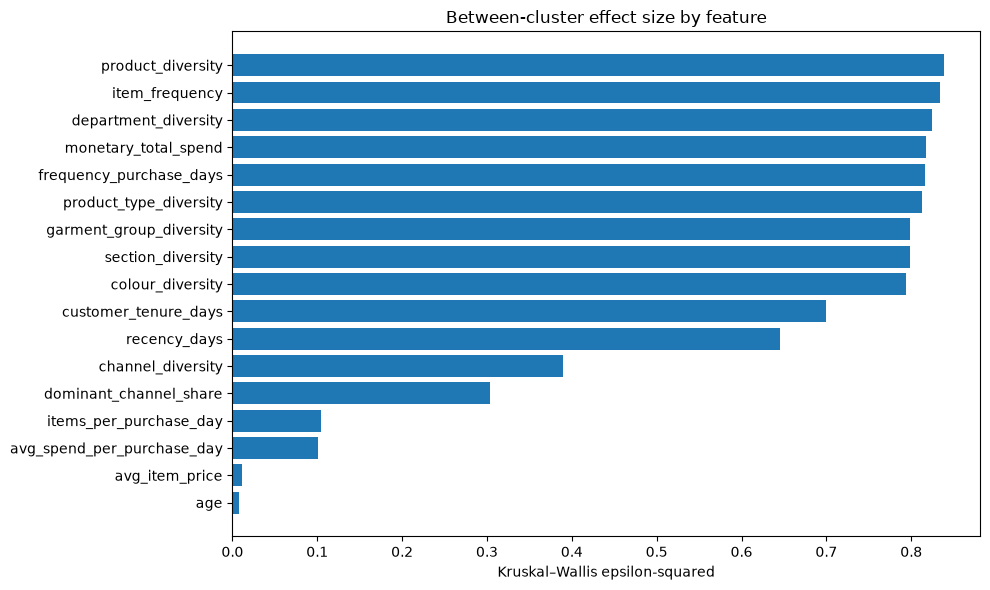

In [11]:
if len(kw_results):
    plot_df = kw_results.sort_values(
        "epsilon_squared"
    )

    fig, ax = plt.subplots(
        figsize=(10, max(6, len(plot_df) * 0.35))
    )

    ax.barh(
        plot_df["feature"],
        plot_df["epsilon_squared"]
    )
    ax.set_xlabel("Kruskal–Wallis epsilon-squared")
    ax.set_title("Between-cluster effect size by feature")

    fig.tight_layout()
    fig.savefig(
        FIG_DIR / "04_feature_effect_sizes.png",
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()

## 9. Pairwise post-hoc cho R/F/M

Kruskal–Wallis chỉ nói **ít nhất một cluster khác**.

Với R/F/M, ta chạy pairwise Mann–Whitney U trên sample cố định và Bonferroni correction để biết cặp cluster nào khác nhau.

Đây là phần bổ sung cho báo cáo; không dùng để tự động đặt tên cluster.

In [12]:
PAIRWISE_FEATURES = [
    f for f in [
        "recency_days",
        "frequency_purchase_days",
        "monetary_total_spend"
    ]
    if f in profile.columns
]

pair_rows = []

pairs = list(itertools.combinations(CLUSTERS, 2))
n_tests = max(1, len(pairs) * len(PAIRWISE_FEATURES))

for feature in PAIRWISE_FEATURES:
    for c1, c2 in pairs:
        s1 = pd.to_numeric(
            profile.loc[
                profile["cluster_id"] == c1,
                feature
            ],
            errors="coerce"
        ).dropna()

        s2 = pd.to_numeric(
            profile.loc[
                profile["cluster_id"] == c2,
                feature
            ],
            errors="coerce"
        ).dropna()

        if len(s1) > PAIRWISE_SAMPLE_PER_CLUSTER:
            s1 = s1.sample(
                PAIRWISE_SAMPLE_PER_CLUSTER,
                random_state=RANDOM_STATE + int(c1)
            )

        if len(s2) > PAIRWISE_SAMPLE_PER_CLUSTER:
            s2 = s2.sample(
                PAIRWISE_SAMPLE_PER_CLUSTER,
                random_state=RANDOM_STATE + int(c2)
            )

        U, p = mannwhitneyu(
            s1,
            s2,
            alternative="two-sided"
        )

        p_bonf = min(1.0, p * n_tests)

        pair_rows.append({
            "feature": feature,
            "cluster_a": c1,
            "cluster_b": c2,
            "median_a": s1.median(),
            "median_b": s2.median(),
            "mannwhitney_U": U,
            "p_value": p,
            "bonferroni_p": p_bonf,
            "significant_05": p_bonf < 0.05
        })

pairwise_results = pd.DataFrame(pair_rows)

display(pairwise_results.head(20))
pairwise_results.to_csv(
    TABLE_DIR / "09_pairwise_rfm_mannwhitney.csv",
    index=False
)

,feature,cluster_a,cluster_b,median_a,median_b,mannwhitney_U,p_value,bonferroni_p,significant_05
0,recency_days,0,1,551.000000,26.000000,399578447.0,0.0,0.0,True
1,recency_days,0,2,551.000000,122.000000,399745484.5,0.0,0.0,True
2,recency_days,0,3,551.000000,57.000000,397482218.5,0.0,0.0,True
3,recency_days,1,2,26.000000,122.000000,74699289.5,0.0,0.0,True
4,recency_days,1,3,26.000000,57.000000,130567899.0,0.0,0.0,True
5,recency_days,2,3,122.000000,57.000000,267136353.5,0.0,0.0,True
6,frequency_purchase_days,0,1,1.000000,24.000000,104853.5,0.0,0.0,True
7,frequency_purchase_days,0,2,1.000000,2.000000,122996722.0,0.0,0.0,True
8,frequency_purchase_days,0,3,1.000000,10.000000,3457186.0,0.0,0.0,True
9,frequency_purchase_days,1,2,24.000000,2.000000,399356991.5,0.0,0.0,True


# G. PROFILE STATES

## 10. Chuyển robust score thành High / Medium / Low

Đây là bước giúp naming rule có thể audit.

Ví dụ:

- `recency_days score <= -0.5` → **Active**
- `recency_days score >= +0.5` → **Inactive**
- `frequency score >= +0.5` → High Frequency
- `monetary score >= +0.5` → High Value

Không dùng threshold absolute như “mua > 10 lần = loyal” vì threshold đó không xuất phát từ distribution H&M.

In [13]:
def level(score):
    if pd.isna(score):
        return "Unknown"
    if score >= PROFILE_THRESHOLD:
        return "High"
    if score <= -PROFILE_THRESHOLD:
        return "Low"
    return "Medium"

def recency_state(score):
    if pd.isna(score):
        return "Unknown"
    if score <= -PROFILE_THRESHOLD:
        return "Active"
    if score >= PROFILE_THRESHOLD:
        return "Inactive"
    return "Moderately Active"

state_rows = []

for cluster_id in CLUSTERS:
    row = {
        "cluster_id": cluster_id
    }

    for f in profile_score.columns:
        score = profile_score.loc[cluster_id, f]
        row[f"{f}_state"] = (
            recency_state(score)
            if f == "recency_days"
            else level(score)
        )

    state_rows.append(row)

profile_states = pd.DataFrame(state_rows)
display(profile_states)

profile_states.to_csv(
    TABLE_DIR / "10_cluster_profile_states.csv",
    index=False
)

,cluster_id,age_state,avg_item_price_state,avg_spend_per_purchase_day_state,channel_diversity_state,colour_diversity_state,customer_tenure_days_state,department_diversity_state,dominant_channel_share_state,frequency_purchase_days_state,garment_group_diversity_state,item_frequency_state,items_per_purchase_day_state,monetary_total_spend_state,product_diversity_state,product_type_diversity_state,recency_days_state,section_diversity_state
0,0,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Inactive,Medium
1,1,Medium,Medium,High,High,High,High,High,Low,High,High,High,Medium,High,High,High,Moderately Active,High
2,2,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Moderately Active,Medium
3,3,Medium,Medium,Medium,High,High,High,High,Low,High,High,High,Medium,High,High,High,Moderately Active,High


# H. AUDITABLE SEGMENT NAMING

## 11. Naming logic

Tên business chính dựa trước hết trên RFM:

### High-Value Loyal
- Active
- High Frequency
- High Monetary

### High-Value At-Risk
- Inactive
- Frequency hoặc Monetary cao

### Recent / New Buyers
- Active
- Low Frequency
- Monetary không cao

### Dormant Low-Value
- Inactive
- Low Frequency
- Low Monetary

### Frequent Core
- Không inactive
- High Frequency
- Monetary chưa cao

### High-Spend Occasional
- Không inactive
- High Monetary
- Frequency chưa cao

### Active Developing
- Active/Moderately Active
- chưa đạt High F + High M

### Regular / Transitional
- các trường hợp còn lại

Extended features **không thay thế RFM trong tên chính**, nhưng được dùng làm descriptor bổ sung như:
- Broad Fashion Interest
- Premium Item Preference
- Fast Repeat Cycle
- Single-Channel Oriented

Nếu hai cluster nhận cùng một business name, notebook **không giả vờ rằng chúng giống hệt nhau**: tên được gắn thêm `Cluster <id>` và cờ `duplicate_name_flag=True`. Đây là tín hiệu cần kiểm tra lại interpretability.

In [14]:
score_lookup = profile_score.copy()

def get_score(cluster_id, feature):
    if feature not in score_lookup.columns:
        return np.nan
    return score_lookup.loc[cluster_id, feature]

def base_segment_name(cluster_id):
    r = get_score(cluster_id, "recency_days")
    f = get_score(cluster_id, "frequency_purchase_days")
    m = get_score(cluster_id, "monetary_total_spend")

    active = pd.notna(r) and r <= -PROFILE_THRESHOLD
    inactive = pd.notna(r) and r >= PROFILE_THRESHOLD

    high_f = pd.notna(f) and f >= PROFILE_THRESHOLD
    low_f = pd.notna(f) and f <= -PROFILE_THRESHOLD

    high_m = pd.notna(m) and m >= PROFILE_THRESHOLD
    low_m = pd.notna(m) and m <= -PROFILE_THRESHOLD

    # Inactive / lapsed with low spend & frequency
    if inactive and not high_f and not high_m:
        return "Dormant Low-Value"

    # Top VIP: extreme frequency and monetary spend
    if not inactive and high_f and high_m and (f >= 2.0 or m >= 2.0):
        return "High-Value Loyal"

    # Core repeat buyers: solid frequency and steady basket
    if not inactive and high_f:
        return "Frequent Core"

    if inactive and (high_f or high_m):
        return "High-Value At-Risk"

    if active and low_f and not high_m:
        return "Recent / New Buyers"

    if not inactive and high_m and not high_f:
        return "High-Spend Occasional"

    # Active / recent but low frequency/spend so far
    if active or (pd.notna(r) and r < PROFILE_THRESHOLD):
        return "Active Developing"

    return "Regular / Transitional"

def extended_descriptors(cluster_id):
    descriptors = []

    fashion_feature = None
    for f in [
        "garment_group_diversity",
        "product_type_diversity",
        "product_diversity"
    ]:
        if f in score_lookup.columns:
            fashion_feature = f
            break

    if fashion_feature:
        s = get_score(cluster_id, fashion_feature)
        if pd.notna(s) and s >= PROFILE_THRESHOLD:
            descriptors.append("Broad Fashion Interest")
        elif pd.notna(s) and s <= -PROFILE_THRESHOLD:
            descriptors.append("Narrow Fashion Breadth")

    if "avg_item_price" in score_lookup.columns:
        s = get_score(cluster_id, "avg_item_price")
        if pd.notna(s) and s >= PROFILE_THRESHOLD:
            descriptors.append("Premium Item Preference")
        elif pd.notna(s) and s <= -PROFILE_THRESHOLD:
            descriptors.append("Lower-Price Preference")

    if "mean_interpurchase_days" in score_lookup.columns:
        s = get_score(cluster_id, "mean_interpurchase_days")
        if pd.notna(s) and s <= -PROFILE_THRESHOLD:
            descriptors.append("Fast Repeat Cycle")
        elif pd.notna(s) and s >= PROFILE_THRESHOLD:
            descriptors.append("Slow Repeat Cycle")

    if "dominant_channel_share" in score_lookup.columns:
        s = get_score(cluster_id, "dominant_channel_share")
        if pd.notna(s) and s >= PROFILE_THRESHOLD:
            descriptors.append("Single-Channel Oriented")

    if "items_per_purchase_day" in score_lookup.columns:
        s = get_score(cluster_id, "items_per_purchase_day")
        if pd.notna(s) and s >= PROFILE_THRESHOLD:
            descriptors.append("High Purchase-Day Intensity")

    return descriptors

naming_rows = []

for cluster_id in CLUSTERS:
    base = base_segment_name(cluster_id)
    descriptors = extended_descriptors(cluster_id)

    naming_rows.append({
        "cluster_id": cluster_id,
        "base_segment_name": base,
        "segment_descriptor": " · ".join(descriptors) if descriptors else "No strong extended descriptor"
    })

segment_names = pd.DataFrame(naming_rows)

duplicate_base_names = (
    segment_names["base_segment_name"]
    .value_counts()
)
duplicate_base_names = set(
    duplicate_base_names[
        duplicate_base_names > 1
    ].index
)

segment_names["duplicate_name_flag"] = (
    segment_names["base_segment_name"]
    .isin(duplicate_base_names)
)

segment_names["proposed_segment_name"] = segment_names.apply(
    lambda r:
        f"{r['base_segment_name']} — Cluster {r['cluster_id']}"
        if r["duplicate_name_flag"]
        else r["base_segment_name"],
    axis=1
)

display(segment_names)

segment_names.to_csv(
    TABLE_DIR / "11_proposed_segment_names.csv",
    index=False
)

,cluster_id,base_segment_name,segment_descriptor,duplicate_name_flag,proposed_segment_name
0,0,Dormant Low-Value,No strong extended descriptor,False,Dormant Low-Value
1,1,High-Value Loyal,Broad Fashion Interest,False,High-Value Loyal
2,2,Active Developing,No strong extended descriptor,False,Active Developing
3,3,Frequent Core,Broad Fashion Interest,False,Frequent Core


# I. NAMING EVIDENCE TABLE

## 12. Tập hợp R/F/M state + descriptors + economic contribution

Đây là bảng nên dùng trực tiếp trong phần “Đặt tên phân khúc” của báo cáo.

In [15]:
naming_evidence = (
    segment_names
    .merge(
        profile_states,
        on="cluster_id",
        how="left"
    )
    .merge(
        cluster_size[[
            "cluster_id",
            "customers",
            "pct_customers",
            "pct_observed_spend",
            "spend_share_index"
        ]],
        on="cluster_id",
        how="left"
    )
)

core_score_cols = [
    c for c in [
        "recency_days",
        "frequency_purchase_days",
        "monetary_total_spend"
    ]
    if c in profile_score.columns
]

core_scores = (
    profile_score[core_score_cols]
    .reset_index()
    .rename(columns={
        f: f"{f}_robust_score"
        for f in core_score_cols
    })
)

naming_evidence = naming_evidence.merge(
    core_scores,
    on="cluster_id",
    how="left"
)

display(naming_evidence)
naming_evidence.to_csv(
    TABLE_DIR / "12_segment_naming_evidence.csv",
    index=False
)

,cluster_id,base_segment_name,segment_descriptor,duplicate_name_flag,proposed_segment_name,age_state,avg_item_price_state,avg_spend_per_purchase_day_state,channel_diversity_state,colour_diversity_state,customer_tenure_days_state,department_diversity_state,dominant_channel_share_state,frequency_purchase_days_state,garment_group_diversity_state,item_frequency_state,items_per_purchase_day_state,monetary_total_spend_state,product_diversity_state,product_type_diversity_state,recency_days_state,section_diversity_state,customers,pct_customers,pct_observed_spend,spend_share_index,recency_days_robust_score,frequency_purchase_days_robust_score,monetary_total_spend_robust_score
0,0,Dormant Low-Value,No strong extended descriptor,False,Dormant Low-Value,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Inactive,Medium,383758,28.170253,6.284533,0.223091,1.137143,-0.285714,-0.248576
1,1,High-Value Loyal,Broad Fashion Interest,False,High-Value Loyal,Medium,Medium,High,High,High,High,High,Low,High,High,High,Medium,High,High,High,Moderately Active,High,138928,10.198190,50.377206,4.939819,-0.360000,3.000000,3.713081
2,2,Active Developing,No strong extended descriptor,False,Active Developing,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Medium,Moderately Active,Medium,560287,41.128592,13.827406,0.336199,-0.082857,-0.142857,-0.121607
3,3,Frequent Core,Broad Fashion Interest,False,Frequent Core,Medium,Medium,Medium,High,High,High,High,Low,High,High,High,Medium,High,High,High,Moderately Active,High,279308,20.502965,29.510855,1.439346,-0.267143,1.000000,0.995411


# J. CATEGORICAL PROFILE-ONLY VARIABLES

## 13. Membership / Fashion News profile

Các biến này giúp hiểu segment nhưng **không được dùng để tuyên bố causal marketing effect**.

club_member_status,ACTIVE,LEFT CLUB,PRE-CREATE,<NA>
cluster_id,,,,
0,84.580126,0.053159,14.246478,1.120237
1,99.532852,0.023034,0.300875,0.143240
2,93.728036,0.030163,6.030481,0.211320
3,98.520272,0.021840,1.324702,0.133186


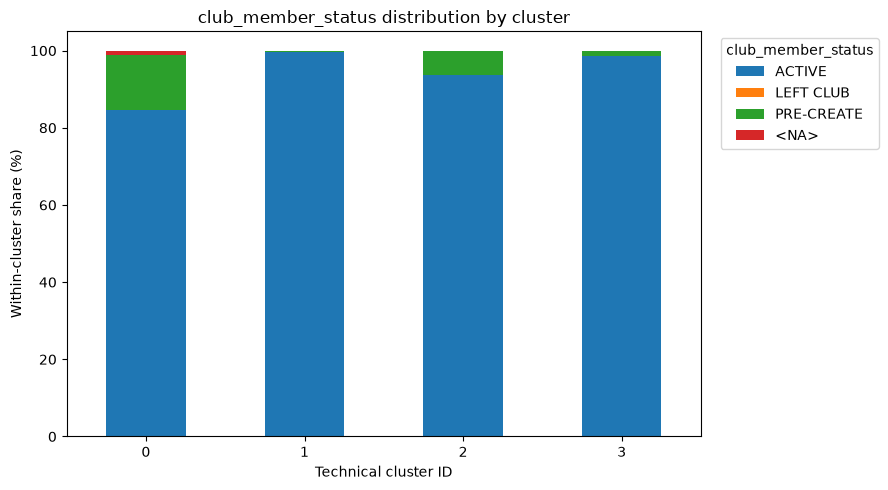

fashion_news_frequency,MONTHLY,NONE,REGULARLY,<NA>
cluster_id,,,,
0,0.129769,68.918172,28.433023,2.519035
1,0.010077,53.337700,46.527698,0.124525
2,0.034268,66.473254,32.635239,0.857239
3,0.048692,57.491014,41.974451,0.485844


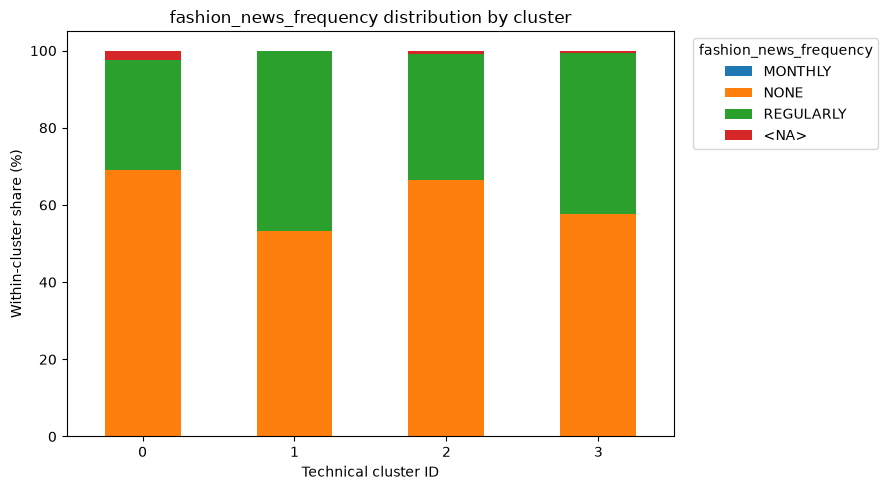

FN,1.0,NaN
cluster_id,,
0,28.468983,71.531017
1,46.403173,53.596827
2,32.594367,67.405633
3,41.895685,58.104315


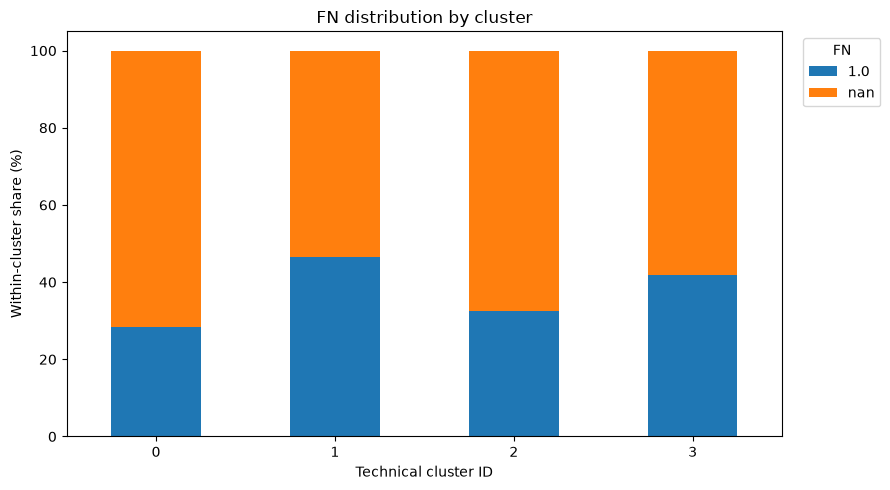

Active,1.0,NaN
cluster_id,,
0,26.927387,73.072613
1,45.846770,54.153230
2,31.907576,68.092424
3,41.207198,58.792802


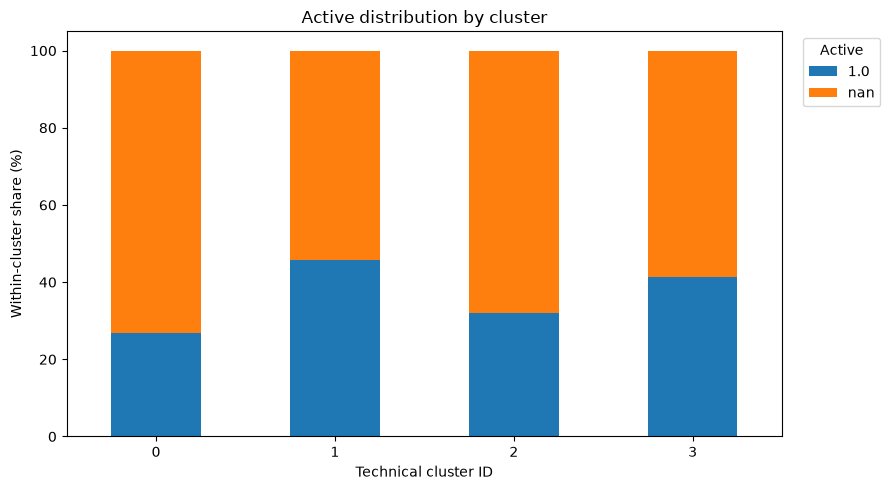

In [16]:
CATEGORICAL_PROFILE = [
    c for c in [
        "club_member_status",
        "fashion_news_frequency",
        "FN",
        "Active"
    ]
    if c in profile.columns
]

for feature in CATEGORICAL_PROFILE:
    tab = pd.crosstab(
        profile["cluster_id"],
        profile[feature],
        normalize="index",
        dropna=False
    ) * 100

    tab.to_csv(
        TABLE_DIR / f"13_categorical_profile_{feature}.csv"
    )

    display(tab)

    fig, ax = plt.subplots(figsize=(9, 5))
    tab.plot(
        kind="bar",
        stacked=True,
        ax=ax
    )
    ax.set_xlabel("Technical cluster ID")
    ax.set_ylabel("Within-cluster share (%)")
    ax.set_title(f"{feature} distribution by cluster")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(
        title=feature,
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )
    fig.tight_layout()

    fig.savefig(
        FIG_DIR / f"05_categorical_{feature}.png",
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()

# K. OPTIONAL GMM MEMBERSHIP CONFIDENCE

## 14. Nếu final model là GMM

GMM có thể cung cấp posterior membership probability.

Nếu model hỗ trợ `predict_proba`, Phase 7 tính:
- `cluster_confidence = max posterior probability`

Điều này giúp nhận biết customer nằm sát biên giữa các segment.

K-Means không có posterior probability, nên không tạo confidence giả.

In [ ]:
segment_assignments = (
    assignments
    .merge(
        segment_names[[
            "cluster_id",
            "proposed_segment_name",
            "segment_descriptor"
        ]],
        on="cluster_id",
        how="left"
    )
)

if MODEL_PATH.exists() and PREPROCESSOR_PATH.exists():
    import joblib
    import sys
    sys.modules['__main__'].OutlierCapper = OutlierCapper
    try:
        final_model = joblib.load(MODEL_PATH)
        preprocessor = joblib.load(PREPROCESSOR_PATH)
    except Exception as _e:
        print(f"Warning loading preprocessor: {_e}")
        final_model = None
        preprocessor = None

    if hasattr(final_model, "predict_proba"):
        def transform_with_saved_bundle(df, bundle):
            X = df[bundle["features"]].copy()
            meta = bundle["transform_meta"].set_index("feature")

            for f in bundle["features"]:
                s = pd.to_numeric(X[f], errors="coerce")
                if meta.loc[f, "transform"] == "log1p":
                    X[f] = np.log1p(s)
                else:
                    X[f] = s

            X_imp = bundle["imputer"].transform(X)
            return bundle["scaler"].transform(X_imp)

        X_full = transform_with_saved_bundle(
            master,
            preprocessor
        )

        posterior = final_model.predict_proba(X_full)

        confidence_df = pd.DataFrame({
            "customer_id": master["customer_id"].values,
            "cluster_confidence": posterior.max(axis=1)
        })

        segment_assignments = segment_assignments.merge(
            confidence_df,
            on="customer_id",
            how="left"
        )

        confidence_summary = (
            segment_assignments
            .groupby("cluster_id")["cluster_confidence"]
            .agg(["mean", "median", "min", "max"])
            .reset_index()
        )

        display(confidence_summary)
        confidence_summary.to_csv(
            TABLE_DIR / "14_gmm_membership_confidence.csv",
            index=False
        )
    else:
        segment_assignments["cluster_confidence"] = np.nan
        print("Final model has no predict_proba; confidence not fabricated.")
else:
    segment_assignments["cluster_confidence"] = np.nan
    print("Saved model/preprocessor not found; confidence step skipped.")

# L. EXPORT FINAL SEGMENT ASSIGNMENTS

## 15. Customer → cluster → business segment

Đây là đầu vào trực tiếp cho Phase 8 Marketing Decision Support.

In [ ]:
SEGMENT_ASSIGN_PATH = (
    RESULT_DIR / "customer_segment_assignments.parquet"
)

segment_assignments.to_parquet(
    SEGMENT_ASSIGN_PATH,
    index=False
)

display(segment_assignments.head())
print("Saved:", SEGMENT_ASSIGN_PATH)

# M. BUSINESS PROFILE SUMMARY

## 16. Tạo bảng một dòng / segment

Bảng này nối:
- tên segment;
- size;
- spending share;
- RFM median;
- extended descriptors.

Rất phù hợp để đưa vào báo cáo.

In [ ]:
core_median_cols = [
    c for c in [
        "recency_days",
        "frequency_purchase_days",
        "monetary_total_spend"
    ]
    if c in cluster_medians.columns
]

core_medians_report = (
    cluster_medians[core_median_cols]
    .reset_index()
)

business_summary = (
    naming_evidence
    .merge(
        core_medians_report,
        on="cluster_id",
        how="left"
    )
)

display(business_summary)
business_summary.to_csv(
    TABLE_DIR / "15_business_segment_summary.csv",
    index=False
)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

plot_df = business_summary.sort_values(
    "pct_observed_spend"
)

ax.barh(
    plot_df["proposed_segment_name"],
    plot_df["pct_observed_spend"]
)

ax.set_xlabel("Observed spending share (%)")
ax.set_title("Observed spending contribution by proposed segment")

fig.tight_layout()
fig.savefig(
    FIG_DIR / "06_segment_spend_share.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

# N. INTERPRETABILITY CHECK

## 17. Rule-based audit

Một segment chỉ nên được coi là đủ dễ diễn giải khi:

- có tên dựa trên R/F/M state;
- không có duplicate business name chưa giải quyết;
- ít nhất một core feature có khác biệt không-negligible;
- cluster không quá nhỏ;
- tên không mâu thuẫn với measured profile.

Notebook tạo cờ để Phase 8 không vô tình xây marketing strategy trên segment khó giải thích.

In [ ]:
effect_lookup = {}

if len(kw_results):
    for _, r in kw_results.iterrows():
        effect_lookup[r["feature"]] = r["epsilon_squared"]

core_effects = [
    effect_lookup.get(f, 0.0)
    for f in [
        "recency_days",
        "frequency_purchase_days",
        "monetary_total_spend"
    ]
    if f in profile.columns
]

max_core_effect = max(core_effects) if core_effects else 0.0

interpretability = naming_evidence[[
    "cluster_id",
    "proposed_segment_name",
    "duplicate_name_flag",
    "pct_customers",
    "pct_observed_spend"
]].copy()

interpretability["tiny_cluster_flag"] = (
    interpretability["pct_customers"] < 1.0
)

interpretability["core_rfm_global_effect_max"] = (
    max_core_effect
)

interpretability["interpretable_for_phase8"] = (
    (~interpretability["duplicate_name_flag"])
    & (~interpretability["tiny_cluster_flag"])
    & (interpretability["core_rfm_global_effect_max"] >= 0.01)
)

display(interpretability)

interpretability.to_csv(
    TABLE_DIR / "16_segment_interpretability_check.csv",
    index=False
)

# O. VALIDATION

## 18. Điều kiện cuối Phase 7

In [ ]:
assert len(segment_assignments) == len(assignments)
assert segment_assignments["customer_id"].duplicated().sum() == 0
assert segment_assignments["proposed_segment_name"].isna().sum() == 0

assert SEGMENT_ASSIGN_PATH.exists()
assert (TABLE_DIR / "12_segment_naming_evidence.csv").exists()
assert (TABLE_DIR / "15_business_segment_summary.csv").exists()

print("Phase 7 validation: PASSED")

# P. REPORT-READY CONCLUSION TEMPLATE

## 19. Kết luận Phase 7

Sau khi chạy notebook, điền số thực tế:

> Mô hình cuối tạo ra ... cluster với quy mô từ ...% đến ...% tổng số khách hàng. Tỷ trọng doanh thu quan sát không phân bố đồng đều giữa các cluster; cluster ... chiếm ...% khách hàng nhưng đóng góp ...% tổng observed spending, cho thấy sự khác biệt rõ về customer value.
>
> Cluster profile được đánh giá chủ yếu bằng median và robust profile score do các biến hành vi có phân bố lệch. R/F/M cùng các extended features được so sánh với median và IQR của toàn population để xác định trạng thái tương đối High/Medium/Low.
>
> Kruskal–Wallis cho thấy các feature ... khác biệt giữa các cluster với FDR-adjusted p-value < 0.05. Tuy nhiên, do cỡ mẫu lớn, nghiên cứu không dựa riêng vào p-value mà sử dụng epsilon-squared để đánh giá độ lớn khác biệt. Các feature có effect size lớn nhất gồm ....
>
> Dựa trên profile định lượng, các cluster được đề xuất tên .... Việc đặt tên tuân theo rule công khai dựa trước hết trên Recency, Frequency và Monetary, sau đó dùng extended features để bổ sung descriptor. Cluster ID không được sử dụng như một dấu hiệu về mức độ giá trị.
>
> Những tên này là cách diễn giải business của cấu trúc phân cụm, không phải ground-truth label. Chúng sẽ được dùng làm đầu vào cho Marketing Decision Support ở Phase 8.

# Q. Không được kết luận ở Phase 7

Không viết:

> “High-Value Loyal chắc chắn trung thành trong tương lai.”

Tên này mô tả **historical behavioral profile**, không đảm bảo hành vi tương lai.

Không viết:

> “Age gây ra cluster.”

Nếu age chỉ dùng profile, nó không tạo cluster.

Không viết:

> “p < 0.05 nên khác biệt rất lớn.”

Với dataset lớn phải đọc effect size.

Không viết:

> “Segment X nên nhận voucher 20%.”

Phase 7 chưa có causal marketing evidence để quyết định mức ưu đãi tối ưu.

# R. Điều kiện chuyển sang Phase 8

Chỉ chuyển sang **Phase 8 — Marketing Decision Support** khi:

- [ ] Customer/spending share theo cluster đã tính.
- [ ] Cluster medians đã sinh.
- [ ] Robust profile heatmap đã sinh.
- [ ] RFM/selected-feature boxplots đã kiểm tra.
- [ ] Kruskal–Wallis + effect size đã hoàn tất.
- [ ] Pairwise RFM validation đã hoàn tất.
- [ ] Profile state table đã sinh.
- [ ] Naming rule đã chạy.
- [ ] Segment naming evidence table đã sinh.
- [ ] Interpretability check đã chạy.
- [ ] `customer_segment_assignments.parquet` đã lưu.
- [ ] Phase 7 validation PASSED.

## Phase 8 sẽ làm gì?

1. Xác định **marketing objective** cho từng segment từ measured profile.
2. Tách:
   - segment-level strategy;
   - individual customer context.
3. Không code cứng `cluster_id → voucher`.
4. Xây rule:
   - segment profile → business diagnosis;
   - diagnosis → marketing objective;
   - customer product/category history → personalized context.
5. Demo nhập `customer_id`.
6. Trả:
   - segment;
   - lý do;
   - customer-specific behavior;
   - suggested marketing action category;
   - KPI nên theo dõi.
7. Tạo bảng strategy cho báo cáo.
8. Ghi rõ recommendation là **decision support**, chưa phải causal optimal policy.